---
title: Week 5 Challenge 1 KEY
subtitle: DS 2023 | Communicating with Data
---

## Overview

In today's challenge, you will apply what you have learned about histograms.

Use the notebook **Histograms** as your guide.

Work in groups to perform the tasks.

When finished, submit a URL to this notebook in your GitHub repo to today's participation assignment.

## The data set

Today's dataset is the `diamonds` dataset available from Seaborn, originally associated with Hadley Wickham's R **ggplot2** package.

It contains physical measurements, gemological grades, and prices for nearly $54,000$ round diamonds.

Each row is an observation for a single diamond.

**Data dictionary**

| Variable | Data Type | Domain / Range | Description |
|---|---|---|---|
| carat | Continuous | 0.2 – 5.01 | Physical weight of the diamond. |
| cut | Categorical (Ordinal) | Fair, Good, Very Good, Premium, Ideal | Quality of the cut, lowest to highest. |
| color | Categorical (Ordinal) | J – D | Color grade, worst to best. |
| clarity | Categorical (Ordinal) | I1 – IF | Clarity grade, worst to best. |
| depth | Continuous | 43 – 79 | Total depth as a percentage of diameter. |
| table | Continuous | 43 – 95 | Width of the top facet as a percentage of diameter. |
| price | Integer | $326 – $18,823 | Retail price in US dollars. |

We will work mostly with `price` and `carat`, both of which are ratio measures and therefore good candidates for a histogram.

## Set Up

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
diamonds = sns.load_dataset('diamonds')
diamonds.info()
diamonds.index.name = 'obs_id'
diamonds.head()

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB


,carat,cut,color,clarity,depth,table,price,x,y,z
obs_id,,,,,,,,,,
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


## Tasks

### Task 1

Create a histogram of `price` using $30$ bins.

Describe the shape of the distribution in a sentence.

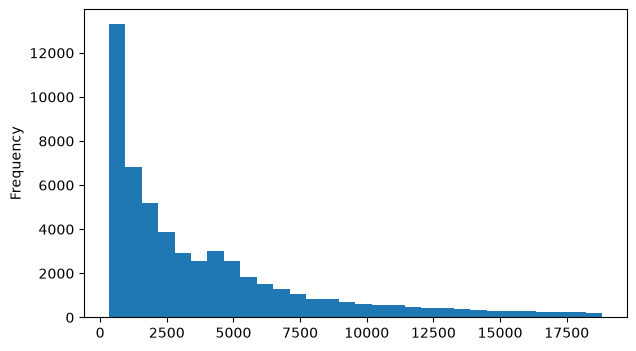

In [3]:
diamonds.price.plot.hist(bins=30, figsize=(7,4))
# plt.xlabel('price')
plt.show()

**Answer**: The distribution is strongly right skewed. Most diamonds are inexpensive, and a long thin tail extends toward $\$18{,}823$.

### Task 2

Compute the mean and the median of `price`.

Why are they so far apart? Which one would you report, and why?

In [4]:
print('mean  ', round(diamonds.price.mean()))
print('median', round(diamonds.price.median()))

mean   3933
median 2401


**Answer**: The mean is $3933$ and the median is $2401$, a difference of over $\$1,500$.

The mean is pulled upward by the long right tail, because a small number of very expensive diamonds contribute disproportionately to the sum.

For a skewed distribution like this one, the median is the better summary of a typical diamond. The histogram is what tells us the distribution is skewed in the first place.

### Task 3

Apply a log transformation to `price` and plot a histogram of the result.

Use $30$ bins.

Hint: Apply a log to the variable itself, _not_ to the plot by setting `logx` or `logy` to `True`.

Did the transformation help?

Hint: Use `.apply(np.log)`.

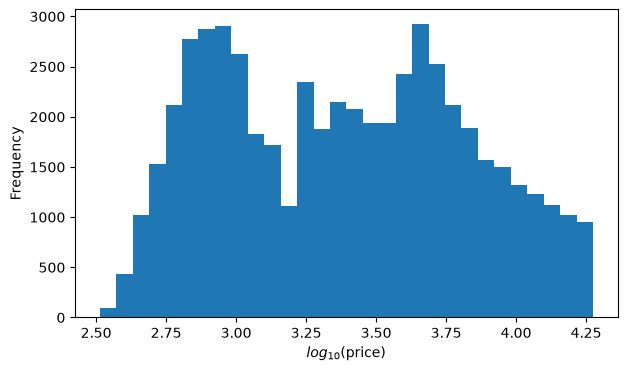

In [5]:
diamonds.price.apply(np.log10).plot.hist(bins=30, figsize=(7,4))
plt.xlabel('$log_{10}$(price)')
plt.show()

**Answer**: Yes. The skew falls from $1.62$ to $0.12$, and the transformed distribution is nearly symmetric.

Note that it is also now visibly bimodal, which the raw histogram did not show.

Transformations are evaluated by drawing another histogram, not by assuming they worked.

### Task 4

Now plot a histogram of `carat` using $30$ bins.

Then plot the same variable using $200$ bins.

Restrict the data to diamonds of $2.1$ carats or less so that the tail does not compress the plot.

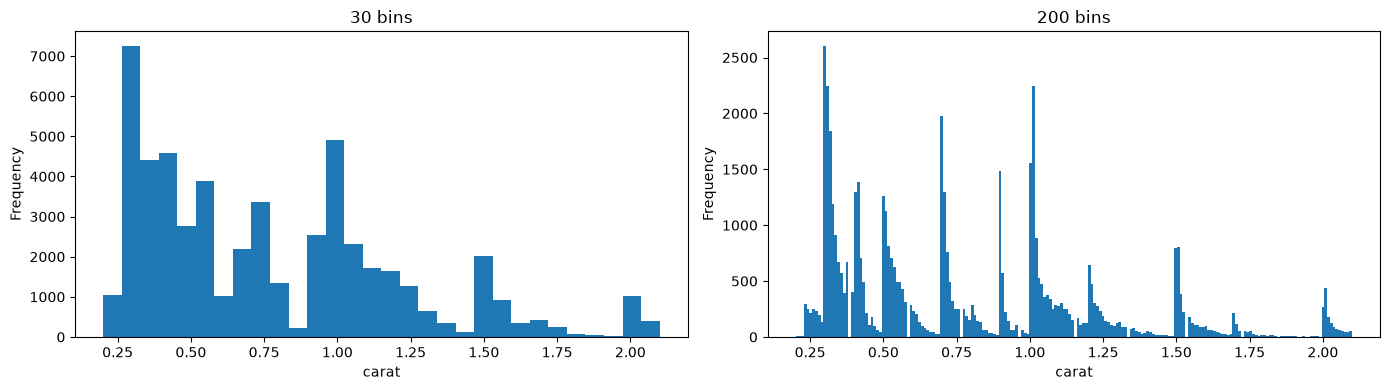

In [6]:
small = diamonds.query('carat <= 2.1')

fig, ax = plt.subplots(1, 2, figsize=(14, 4))

small.carat.plot.hist(bins=30, ax=ax[0], title='30 bins')
small.carat.plot.hist(bins=200, ax=ax[1], title='200 bins')

for a in ax:
    a.set_xlabel('carat')

plt.tight_layout()
plt.show()

### Task 5

The $200$ bin version shows a pattern that the $30$ bin version only hints at.

Describe the pattern. What do you think causes it?

In [7]:
diamonds.carat.value_counts().head(8).sort_index()

carat
0.30    2604
0.31    2249
0.32    1840
0.41    1382
0.70    1981
0.90    1485
1.00    1558
1.01    2242
Name: count, dtype: int64

In [8]:
print('diamonds at exactly 1.00 carat:', (diamonds.carat == 1.00).sum())
print('diamonds at exactly 0.99 carat:', (diamonds.carat == 0.99).sum())

diamonds at exactly 1.00 carat: 1558
diamonds at exactly 0.99 carat: 23


**Answer**: At $200$ bins the distribution resolves into a series of sharp spikes at $0.3$, $0.4$, $0.5$, $0.7$, $0.9$, $1.0$, $1.5$, and $2.0$ carats, each followed by a tail that decays to the right.

The cause is probably the market. 

Round carat weights carry a price premium, so a cutter with a rough stone slightly above a threshold will cut to preserve the round weight rather than to maximize optical quality.

The effect is dramatic at the one carat boundary: there are $1558$ diamonds at exactly $1.00$ carats and only $23$ at $0.99$.

This is a **heaping** artifact.

It is invisible in any summary statistic. 

Only a histogram at sufficient resolution reveals it.

### Task 6

Create a set of histograms of `price`, one for each value of `cut`, arranged as subplots.

Hint: first build a wide table in which each column holds the prices for one cut.

```python
price_by_cut = pd.DataFrame({
    cut: g.price.reset_index(drop=True)
    for cut, g in diamonds.groupby('cut', observed=True)
})
```

The hint was way too complicated!

In [9]:
price_by_cut = diamonds.pivot(columns='cut', values='price')
price_by_cut

cut,Ideal,Premium,Very Good,Good,Fair
obs_id,,,,,
0,326.0,NaN,NaN,NaN,NaN
1,NaN,326.0,NaN,NaN,NaN
2,NaN,NaN,NaN,327.0,NaN
3,NaN,334.0,NaN,NaN,NaN
4,NaN,NaN,NaN,335.0,NaN
...,...,...,...,...,...
53935,2757.0,NaN,NaN,NaN,NaN
53936,NaN,NaN,NaN,2757.0,NaN
53937,NaN,NaN,2757.0,NaN,NaN


> [!IMPORTANT]
>
> The table above is the result of an **unaggregated pivot** with no index specified.
>
> Each index is the unique ID for the observation.
>
> Since each observation can have only one `cut` value, the dataframe has many null values.
>
> However, any vertical (column-wise) operations will work as long as the nulls are not converted to values.
>
> The operations drop the nulls before being applied.
>


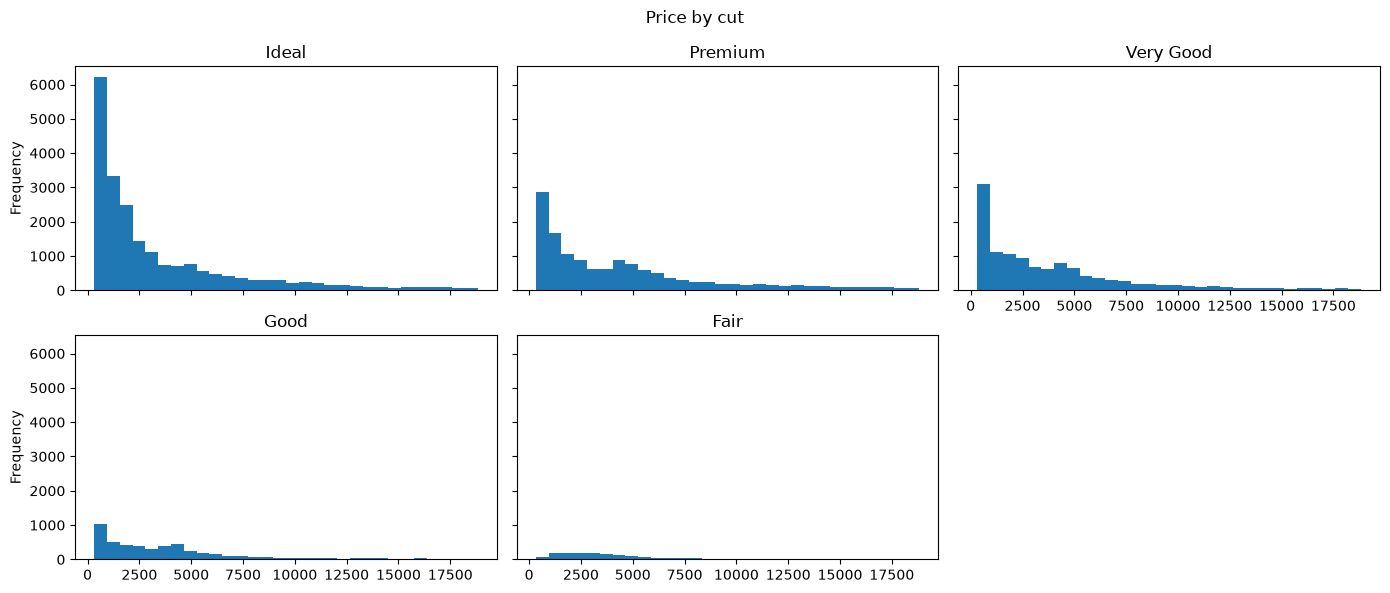

In [12]:
price_by_cut.plot.hist(
    subplots=True, 
    layout=(2,3), 
    figsize=(14,6), 
    bins=30,                   
    sharex=True, 
    sharey=True, 
    legend=False,                   
    color='tab:blue', 
    title=list(price_by_cut.columns)
)
plt.suptitle('Price by cut')
plt.tight_layout()
plt.show()

**Answer**: Every cut shows the same right skewed shape. The panels differ mostly in height, because the cuts have very different numbers of diamonds.

### Bonus

The panels above are hard to compare because `Ideal` contains $21{,}551$ diamonds and `Fair` contains only $1610$.

This makes them hard to compare. 

Redraw them so that each panel is comparable regardless of how many diamonds it contains.

Hint: `density=True`.

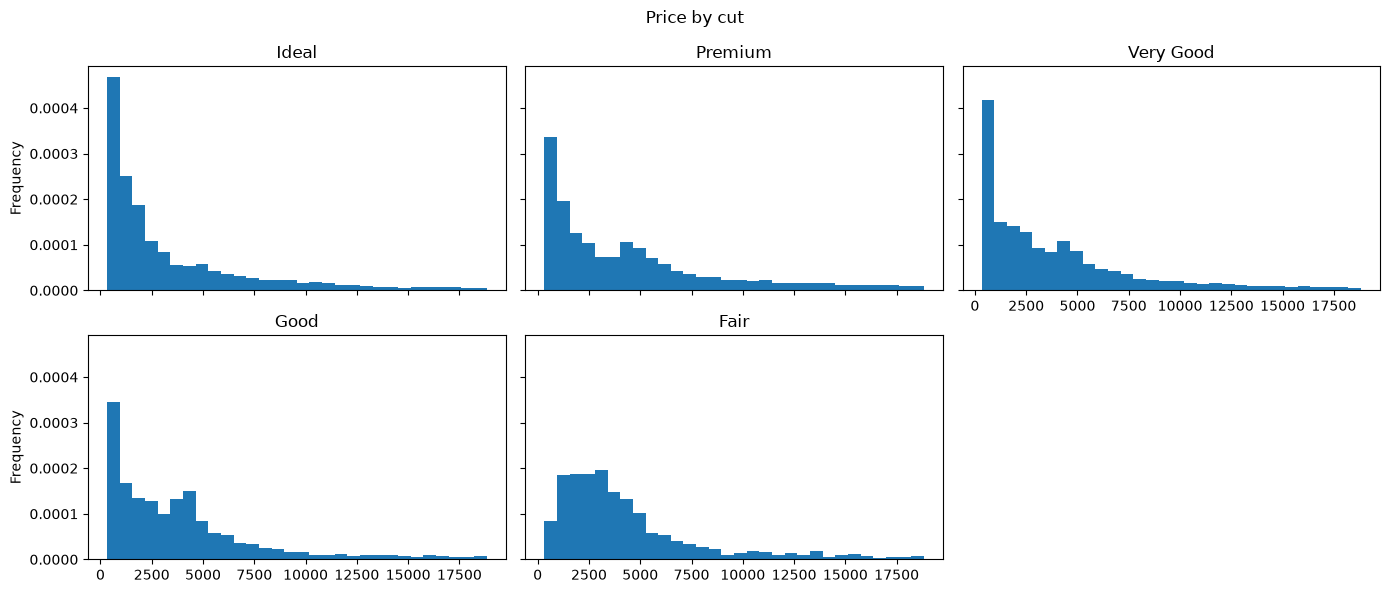

In [11]:
price_by_cut.plot.hist(
    subplots=True, 
    layout=(2,3), 
    figsize=(14,6), 
    bins=30,                   
    sharex=True, 
    sharey=True, 
    legend=False,                   
    color='tab:blue', 
    title=list(price_by_cut.columns),
    density=True
)
plt.suptitle('Price by cut')
plt.tight_layout()
plt.show()

**Answer**: With `density=True` each panel encloses an area of $1$, so the panels can be compared on shape rather than on count.

Now a real difference is visible. `Ideal` diamonds are far more concentrated at the low end than `Fair` ones: $59.6\%$ of `Ideal` diamonds are priced under $\$2500$, against only $35.1\%$ of `Fair` diamonds. The median `Ideal` diamond costs $\$1810$ and the median `Fair` diamond costs $\$3282$.

This is worth pausing over, because it runs against expectation. The best cut grade is associated with the *lower* prices. The explanation is that cut quality is not the main driver of price here, weight is, and `Ideal` diamonds in this dataset tend to be smaller stones.